In [1]:
import pandas as pd
import requests
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt
import seaborn as sns
import time

sns.set_theme(style="whitegrid")

In [4]:
# 1.

wiki_url = 'https://en.wikipedia.org/wiki/List_of_Academy_Award-winning_films'
headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)'}

response = requests.get(wiki_url, headers=headers)
soup = BeautifulSoup(response.content, 'html.parser')

table = soup.find('class', {'class': 'wikitable'})
tables = soup.find_all('table', {'class': 'wikitable'})

target_table = tables[0] if tables else None

movies_list = []

if target_table:
  for row in target_table.find_all('tr')[1:]:
    cols = row.find_all(['td', 'th'])
    if len(cols) >= 2:
      title = cols[0].get_text(strip=True)
      year = cols[1].get_text(strip=True)
      title = title.split('[')[0]
      year = ''.join(filter(str.isdigit, year))[:4]

      if title and year:
        movies_list.append(
            {'year': year, 'title': title, 'status': 'Winner'}
        )

df_wiki = pd.DataFrame(movies_list)
print(f'Собрано строк с Википедии: {len(df_wiki)}')
display(df_wiki.head())

Собрано строк с Википедии: 1401


,year,title,status
0,2025,One Battle After Another,Winner
1,2025,Sinners,Winner
2,2025,Frankenstein,Winner
3,2025,KPop Demon Hunters,Winner
4,2025,Hamnet,Winner


In [7]:
API_KEY = 'da40f629'
api_data = []

for index, row in df_wiki.iterrows():
  title = row['title']
  year = row['year']

  url = f'http://www.omdbapi.com/?t={title}&y={year}&apikey={API_KEY}'
  res = requests.get(url).json()

  if res.get('Response') == 'True':
    api_data.append({
        'title': title,
        'box_office': res.get('BoxOffice'),
        'metascore': res.get('Metascore'),
        'imdb_rating': res.get('imdbRating'),
        'genre': res.get('Genre'),
    })
  time.sleep(0.1)

df_api = pd.DataFrame(api_data)
display(df_api.head())

,title,box_office,metascore,imdb_rating,genre
0,One Battle After Another,"$72,918,884",95,7.7,"Action, Crime, Drama"
1,Sinners,"$279,989,632",84,7.5,"Action, Drama, Horror"
2,Frankenstein,N/A,78,7.4,"Drama, Fantasy, Horror"
3,KPop Demon Hunters,"$24,300,000",77,7.4,"Animation, Action, Adventure"
4,Hamnet,"$24,208,900",84,7.8,"Biography, Drama, History"


In [8]:
df_merged = pd.merge(df_wiki, df_api, on='title', how='inner')

df_merged['box_office'] = (
    df_merged['box_office']
    .astype(str)
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False)
)
df_merged['box_office'] = pd.to_numeric(
    df_merged['box_office'], errors='coerce'
)

df_merged['metascore'] = pd.to_numeric(
    df_merged['metascore'], errors='coerce'
)
df_merged['imdb_rating'] = pd.to_numeric(
    df_merged['imdb_rating'], errors='coerce'
)

df_merged = df_merged.drop_duplicates()
df_clean = df_merged.dropna(subset=['box_office', 'metascore'])

df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 496 entries, 0 to 861
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   year         496 non-null    object 
 1   title        496 non-null    object 
 2   status       496 non-null    object 
 3   box_office   496 non-null    float64
 4   metascore    496 non-null    float64
 5   imdb_rating  496 non-null    float64
 6   genre        496 non-null    object 
dtypes: float64(3), object(4)
memory usage: 31.0+ KB


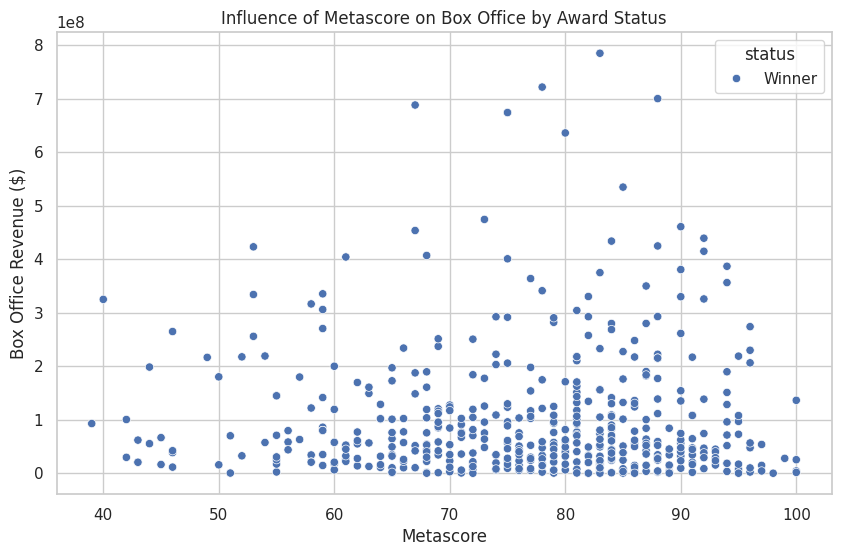

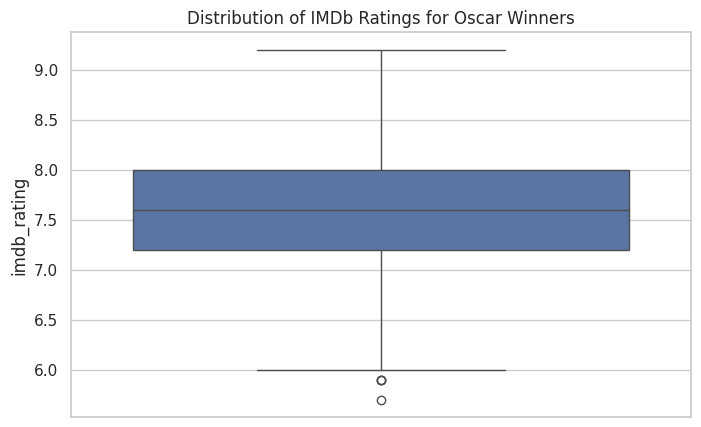

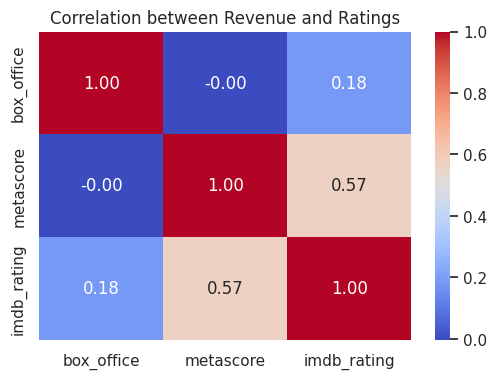

In [10]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_clean, x='metascore', y='box_office', hue='status')
plt.title('Influence of Metascore on Box Office by Award Status')
plt.xlabel('Metascore')
plt.ylabel('Box Office Revenue ($)')
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean, y='imdb_rating')
plt.title('Distribution of IMDb Ratings for Oscar Winners')
plt.show()

plt.figure(figsize=(6, 4))
corr_matrix = df_clean[['box_office', 'metascore', 'imdb_rating']].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation between Revenue and Ratings')
plt.show()